In [82]:
import pymupdf
import pandas as pd 
import glob
import os 

import re
import plotly.express as px
import plotly.graph_objects as go

from plotly.subplots import make_subplots


#### Carregando dados

In [33]:
BASE_PATH = "/home/gustavoreis/Projetos/Homelab/ACartomanteRAG"

df_coletanea_pdfs = pd.read_csv(
    "/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/"
    "Dataset/metadata/obras_machado_assis_deduplicadas.csv"
)

df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Carteira.pdf
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Cartomante.pdf
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Causa_Secreta.pdf
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_chave.pdf
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/A_Chinela_Turca.pdf
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Viver!.pdf
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Várias_Histórias.pdf
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Vênus!_divina_vênus!.pdf
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,Dataset/raw/Última_receita.pdf


transforma path em absoluto 

In [34]:
df_coletanea_pdfs["pdf_path"] = df_coletanea_pdfs["pdf_path"].apply(
    lambda x: os.path.join(BASE_PATH, x)
    if pd.notna(x)
    else None
)
df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...


In [39]:
paths = df_coletanea_pdfs["pdf_path"].dropna()

existentes = paths.apply(os.path.isfile)

print(f"{existentes.sum()} de {len(paths)} existentes")

if not existentes.all():
    print("\nNão encontrados:")
    for path in paths[~existentes]:
        print(path)

257 de 257 existentes


Um pdf não existia dado que em dropna perdemos 1 amostra de 258 para 257 , validando qual :

In [36]:
df_coletanea_pdfs[df_coletanea_pdfs["pdf_path"].isna()]

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
167,O Rei dos Caiporas,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"0,00 KB",8240,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,None


procurando na fonte o pdf nao esta disponivel no server: 

https://dominiopublico.mec.gov.br/pesquisa/DetalheObraForm.do?select_action=&co_obra=17481

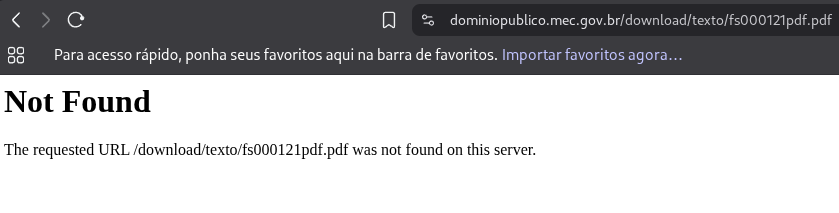

necessario atualizar o crawler de download para lidar quando não houver pdfs. 

Por hora limpar do df


In [40]:
df_coletanea_pdfs.dropna(inplace=True)
df_coletanea_pdfs

,titulo,autor,fonte,formato,tamanho,acessos,url_detalhe,url_download,downloads_encontrados,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"30,24 KB",114102,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"39,64 KB",154851,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,.pdf,"40,80 KB",53202,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"138,02 KB",55648,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"85,09 KB",63578,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"73,30 KB",11632,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,.pdf,"455,17 KB",24726,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"93,37 KB",8184,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,.pdf,"86,65 KB",5506,https://dominiopublico.mec.gov.br/pesquisa/Det...,https://dominiopublico.mec.gov.br/pesquisa/Det...,1,/home/gustavoreis/Projetos/Homelab/ACartomante...


#### Analise quantitativa bruta

removendo colunas não necessárias para essa analise

In [69]:
df_coletanea_infos = df_coletanea_pdfs.copy()
df_coletanea_infos.drop(columns=["formato","url_detalhe","url_download","downloads_encontrados"], inplace=True)
df_coletanea_infos

,titulo,autor,fonte,tamanho,acessos,pdf_path
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"30,24 KB",114102,/home/gustavoreis/Projetos/Homelab/ACartomante...
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"39,64 KB",154851,/home/gustavoreis/Projetos/Homelab/ACartomante...
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"40,80 KB",53202,/home/gustavoreis/Projetos/Homelab/ACartomante...
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"138,02 KB",55648,/home/gustavoreis/Projetos/Homelab/ACartomante...
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"85,09 KB",63578,/home/gustavoreis/Projetos/Homelab/ACartomante...
...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"73,30 KB",11632,/home/gustavoreis/Projetos/Homelab/ACartomante...
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"455,17 KB",24726,/home/gustavoreis/Projetos/Homelab/ACartomante...
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"93,37 KB",8184,/home/gustavoreis/Projetos/Homelab/ACartomante...
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"86,65 KB",5506,/home/gustavoreis/Projetos/Homelab/ACartomante...


In [ ]:
def extrair_metricas_pdf(pdf_path):
    doc = pymupdf.open(pdf_path)

    qtd_paginas = doc.page_count
    qtd_caracteres = 0
    qtd_palavras = 0
    qtd_paragrafos = 0

    for page in doc:
        texto = page.get_text()
       
        qtd_caracteres += len(texto)

        
        palavras = re.findall(r"\b\w+\b", texto, flags=re.UNICODE)
        qtd_palavras += len(palavras)

        blocos = page.get_text("blocks")
        for bloco in blocos:
            texto_bloco = bloco[4].strip()

            if texto_bloco:
                qtd_paragrafos += 1

    doc.close()

    return pd.Series({
        "count_pages": qtd_paginas,
        "count_chars": qtd_caracteres,
        "count_words": qtd_palavras,
        "count_paragraphs": qtd_paragrafos,
    })

In [70]:
df_coletanea_infos[
    [
        "count_pages",
        "count_chars",
        "count_words",
        "count_paragraphs",
    ]
] = df_coletanea_infos["pdf_path"].apply(
    extrair_metricas_pdf
)

In [71]:
df_coletanea_infos

,titulo,autor,fonte,tamanho,acessos,pdf_path,count_pages,count_chars,count_words,count_paragraphs
0,A Carteira,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"30,24 KB",114102,/home/gustavoreis/Projetos/Homelab/ACartomante...,4,7835,1375,37
1,A Cartomante,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"39,64 KB",154851,/home/gustavoreis/Projetos/Homelab/ACartomante...,8,18532,3280,82
2,A Causa Secreta,Machado de Assis,[ua] Universidade da Amazônia - UNAMA,"40,80 KB",53202,/home/gustavoreis/Projetos/Homelab/ACartomante...,8,19875,3497,86
3,A chave,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"138,02 KB",55648,/home/gustavoreis/Projetos/Homelab/ACartomante...,17,37790,6648,582
4,A Chinela Turca,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"85,09 KB",63578,/home/gustavoreis/Projetos/Homelab/ACartomante...,10,21437,3669,107
...,...,...,...,...,...,...,...,...,...,...
253,Viver!,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"73,30 KB",11632,/home/gustavoreis/Projetos/Homelab/ACartomante...,6,15238,2575,11
254,Várias Histórias,Machado de Assis,[bv] Biblioteca Virtual do Estudante Brasileir...,"455,17 KB",24726,/home/gustavoreis/Projetos/Homelab/ACartomante...,56,270751,47267,81
255,Vênus! divina vênus!,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"93,37 KB",8184,/home/gustavoreis/Projetos/Homelab/ACartomante...,9,20308,3467,306
256,Última receita,Machado de Assis,[fs] Universidade Federal de Santa Catarina - ...,"86,65 KB",5506,/home/gustavoreis/Projetos/Homelab/ACartomante...,7,11566,1972,221


graficos 

distribuição dos dados de cada pdf

In [ ]:
metricas = {
    "count_pages": "Quantidade de páginas",
    "count_chars": "Quantidade de caracteres",
    "count_words": "Quantidade de palavras",
    "count_paragraphs": "Quantidade de parágrafos",
}


def plot_distribuicao(df, coluna, titulo):

    dados = pd.to_numeric(
        df[coluna],
        errors="coerce",
    ).dropna()

    media = dados.mean()
    mediana = dados.median()

    fig = make_subplots(
        rows=1,
        cols=2,
        column_widths=[0.75, 0.25],
        subplot_titles=[
            "Distribuição",
            "Boxplot",
        ],
    )

    fig.add_trace(
        go.Histogram(
            x=dados,
            nbinsx=20,
            hovertemplate=(
                f"{titulo}: %{{x:,.0f}}"
                "<br>Obras: %{y}"
                "<extra></extra>"
            ),
        ),
        row=1,
        col=1,
    )

    fig.add_vline(
        x=media,
        line_dash="dash",
        annotation_text=f"Média: {media:,.1f}",
        annotation_position="top",
        row=1,
        col=1,
    )

    fig.add_vline(
        x=mediana,
        line_dash="dot",
        annotation_text=f"Mediana: {mediana:,.1f}",
        annotation_position="bottom",
        row=1,
        col=1,
    )

    fig.add_trace(
        go.Box(
            y=dados,
            boxpoints="outliers",
            name="",
            hovertemplate=(
                f"{titulo}: %{{y:,.0f}}"
                "<extra></extra>"
            ),
        ),
        row=1,
        col=2,
    )

    fig.update_xaxes(
        title_text=titulo,
        row=1,
        col=1,
    )

    fig.update_yaxes(
        title_text="Quantidade de obras",
        row=1,
        col=1,
    )

    fig.update_yaxes(
        title_text=titulo,
        row=1,
        col=2,
    )

    fig.update_layout(
        template="plotly_white",
        height=550,
        width=1200,
        showlegend=False,
        bargap=0.05,
        title={
            "text": f"{titulo} — {len(dados)} obras",
            "x": 0.5,
        },
    )

    fig.show()


for coluna, titulo in metricas.items():
    plot_distribuicao(
        df_coletanea_infos,
        coluna,
        titulo,
    )

top 10 livros por acesso 

In [89]:

def limites_outlier(serie):
    serie = pd.to_numeric(serie, errors="coerce").dropna()

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1

    return (
        q1 - 1.5 * iqr,
        q3 + 1.5 * iqr,
    )




top10 = (
    df_coletanea_infos
    .assign(
        acessos=pd.to_numeric(
            df_coletanea_infos["acessos"],
            errors="coerce",
        )
    )
    .dropna(subset=["acessos"])
    .nlargest(10, "acessos")
    .sort_values("acessos")
    .copy()
)




_, lim_sup_pages = limites_outlier(
    df_coletanea_infos["count_pages"]
)

_, lim_sup_words = limites_outlier(
    df_coletanea_infos["count_words"]
)

top10["outlier_pages"] = (
    top10["count_pages"] > lim_sup_pages
)

top10["outlier_words"] = (
    top10["count_words"] > lim_sup_words
)


top10["label_pages"] = top10.apply(
    lambda x: (
        f"{x['count_pages']:,.0f} ★"
        if x["outlier_pages"]
        else f"{x['count_pages']:,.0f}"
    ),
    axis=1,
)

top10["label_words"] = top10.apply(
    lambda x: (
        f"{x['count_words']:,.0f} ★"
        if x["outlier_words"]
        else f"{x['count_words']:,.0f}"
    ),
    axis=1,
)



fig = make_subplots(
    rows=2,
    cols=2,

    # gráfico superior ocupa as duas colunas
    specs=[
        [{"colspan": 2}, None],
        [{}, {}],
    ],

    subplot_titles=[
        "Top 10 obras por acessos",
        "Quantidade de páginas",
        "Quantidade de palavras",
    ],

    row_heights=[
        0.45,
        0.55,
    ],

    vertical_spacing=0.12,
    horizontal_spacing=0.18,
)




fig.add_trace(
    go.Bar(
        y=top10["titulo"],
        x=top10["acessos"],
        orientation="h",

        text=top10["acessos"],
        texttemplate="%{text:,.0f}",
        textposition="outside",

        hovertemplate=(
            "<b>%{y}</b>"
            "<br>Acessos: %{x:,.0f}"
            "<extra></extra>"
        ),
    ),
    row=1,
    col=1,
)




fig.add_trace(
    go.Bar(
        y=top10["titulo"],
        x=top10["count_pages"],
        orientation="h",

        text=top10["label_pages"],
        textposition="outside",

        customdata=top10[
            [
                "acessos",
                "outlier_pages",
            ]
        ],

        hovertemplate=(
            "<b>%{y}</b>"
            "<br>Páginas: %{x:,.0f}"
            "<br>Acessos: %{customdata[0]:,.0f}"
            "<br>Outlier: %{customdata[1]}"
            "<extra></extra>"
        ),
    ),
    row=2,
    col=1,
)




fig.add_trace(
    go.Bar(
        y=top10["titulo"],
        x=top10["count_words"],
        orientation="h",

        text=top10["label_words"],
        textposition="outside",

        customdata=top10[
            [
                "acessos",
                "outlier_words",
            ]
        ],

        hovertemplate=(
            "<b>%{y}</b>"
            "<br>Palavras: %{x:,.0f}"
            "<br>Acessos: %{customdata[0]:,.0f}"
            "<br>Outlier: %{customdata[1]}"
            "<extra></extra>"
        ),
    ),
    row=2,
    col=2,
)


fig.update_xaxes(
    title_text="Número de acessos",
    row=1,
    col=1,
)

fig.update_xaxes(
    title_text="Páginas",
    row=2,
    col=1,
)

fig.update_xaxes(
    title_text="Palavras",
    row=2,
    col=2,
)



fig.update_layout(
    template="plotly_white",
    height=1100,
    width=1400,
    showlegend=False,

    title={
        "text": (
            "Top 10 obras mais acessadas"
            "<br><sup>"
            "★ indica outlier segundo 1,5 × IQR do corpus"
            "</sup>"
        ),
        "x": 0.5,
        "xanchor": "center",
    },
)

fig.show()

#### Analise Semantica Estrutural

In [60]:
path = df_coletanea_pdfs.loc[1,"pdf_path"]
doc = pymupdf.open(path)
print(path)
print(doc)
for page in doc: # iterate the document pages
    text = page.get_text()
    print(text)

/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/A_Cartomante.pdf
Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/A_Cartomante.pdf')
www.nead.unama.br
1
Universidade da Amazônia
A Cartomante
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-3196 / 210-3181
www.nead.unama.br
E-mail: uvb@unama.br

www.nead.unama.br
2
A Cartomante
de Machado de Assis
Hamlet observa a Horácio que há mais cousas no céu e na terra do que
sonha a nossa filosofia. Era a mesma explicação que dava a bela Rita ao moço
Camilo, numa sexta-feira de novembro de 1869, quando este ria dela, por ter ido na
véspera consultar uma cartomante; a diferença é que o fazia por outras palavras.
— Ria, ria. Os homens são assim; não acreditam em nada. Pois saiba que fui,
e que ela adivinhou o motivo da consulta, antes mesmo que eu lhe dissesse o que
era. Apenas começou a botar as cartas, d

In [44]:
path = df_coletanea_pdfs.loc[100,"pdf_path"]
doc = pymupdf.open(path)
print(path)
print(doc)
for page in doc: # iterate the document pages
    text = page.get_text()
    print(text)

/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Hoje_Avental,_amanhã_Luva.pdf
Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Hoje_Avental,_amanhã_Luva.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Hoje Avental, Amanhã Luva, de Machado de Assis.
Edição de referência: Teatro de Machado de Assis, de Machado de Assis
Martins Fontes, 2003, São Paulo
 
 
HOJE AVENTAL, AMANHÃ LUVA
Comédia em um ato imitada do francês por Machado de Assis.
PERSONAGENS
DURVAL
ROSINHA
BENTO
Rio de Janeiro - Carnaval de 1859.
(Sala elegante. Piano, canapé, cadeiras, uma jarra de flores em uma mesa à direita alta. 
Portas laterais no fundo.)
  
Cena I
ROSINHA (adormecida no canapé);
DURVAL (entrando pela porta do fundo)
DURVAL
Onde está a Sra. Sofia de Melo?... Não vejo ninguém. Depois de dois anos como venho 
encontrar estes sítios! Quem sabe se em vez da palavra dos cumprimentos deverei trazer 
a palavra dos epitáfios! Como tem crescido isto em opulência!

In [45]:
path = df_coletanea_pdfs.loc[200,"pdf_path"]
doc = pymupdf.open(path)
print(path)
print(doc)
for page in doc: # iterate the document pages
    text = page.get_text()
    print(text)

/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Questão_de_vaidade.pdf
Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Questão_de_vaidade.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Questão de vaidade, de Machado de Assis
Edição referência: http://www2.uol.com.br/machadodeassis
Publicado originalmente em Jornal das Famílias 1864
 
I
Suponha o leitor que somos conhecidos velhos. Estamos ambos entre as quatro paredes 
de uma sala; o leitor, sentado em uma cadeira com as pernas sobre a mesa, à moda 
americana, eu, a fio comprido em uma rede do Pará, que se balouça voluptuosamente, à 
moda brasileira, ambos enchendo o ar de leves e caprichosas fumaças, à moda de toda 
gente.
Imagine mais que é noite. A janela aberta deixa entrar as brisas aromáticas do jardim, por 
entre cujos arbustos se descobre a lua surgindo em um límpido horizonte.
Sobre a mesa ferve em aparelho próprio uma pouca de água para fazer uma tintura de 
chá. Não sei

Necessária uma limpeza nesses dados, aparentemente , todos eles começam com um header indicando questões da obra, quem publicou quando e onde  

e.g: 

* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Questão_de_vaidade.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Questão de vaidade, de Machado de Assis
Edição referência: http://www2.uol.com.br/machadodeassis
Publicado originalmente em Jornal das Famílias 1864
 

* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/Hoje_Avental,_amanhã_Luva.pdf')
LITERATURA BRASILEIRA
Textos literários em meio eletrônico
Hoje Avental, Amanhã Luva, de Machado de Assis.
Edição de referência: Teatro de Machado de Assis, de Machado de Assis
Martins Fontes, 2003, São Paulo


* Document('/home/gustavoreis/Projetos/Homelab/ACartomanteRAG/Dataset/raw/A_Cartomante.pdf')
www.nead.unama.br
1
Universidade da Amazônia
A Cartomante
de Machado de Assis
de Machado de Assis
NEAD – NÚCLEO DE EDUCAÇÃO A DISTÂNCIA
Av. Alcindo Cacela, 287 – Umarizal
CEP: 66060-902
Belém – Pará
Fones: (91) 210-3196 / 210-3181
www.nead.unama.br
E-mail: uvb@unama.br

www.nead.unama.br